# 08 · Topological data analysis III: 3D point clouds and adaptive thresholds

Two variations on the previous pipelines.

**A. 3D point cloud (row, column, intensity).** A regular grid of nodes
(one every 3 pixels) is laid over the image, background nodes are dropped,
and each remaining node becomes a 3D point whose third coordinate is its
intensity. All axes are rescaled to [0, 1], so two pixels are close only if
they are near *and* have similar uptake. The alpha filtration is then
computed on this cloud.

**B. Adaptive (quantile) threshold.** A fixed absolute threshold keeps more
or less foreground depending on a scan's overall brightness (calibration,
noise, physiology). Here each image keeps the same fraction of its own
brightest pixels: the threshold is the per-image 50% quantile.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adni_tau.paths import save_figure, save_table
from adni_tau.tda import filtration_3d
from adni_tau.tda.classification import (
    cross_validate_logistic_multiview,
    fit_eval_logistic_multiview,
    run_nearest_template_classification,
    summarize_results,
)
from adni_tau.tda.data import load_all_views
from adni_tau.tda.templates import compute_class_template_tda_quantile, compute_class_templates_for_view
from adni_tau.tda.topology import compute_tda_for_images

plt.rcParams["figure.dpi"] = 90
VIEWS = ["axial", "coronal", "sagittal"]
LOGIT_C = 0.1

data_by_view = load_all_views(VIEWS)
y_train, y_test = data_by_view[VIEWS[0]]["y_train"], data_by_view[VIEWS[0]]["y_test"]

   axial: train (192, 182, 218), test (20, 182, 218)


 coronal: train (192, 182, 182), test (20, 182, 182)


sagittal: train (192, 182, 218), test (20, 182, 218)


## A. 3D point clouds

262 points | H0: 262 features | H1: 442 features


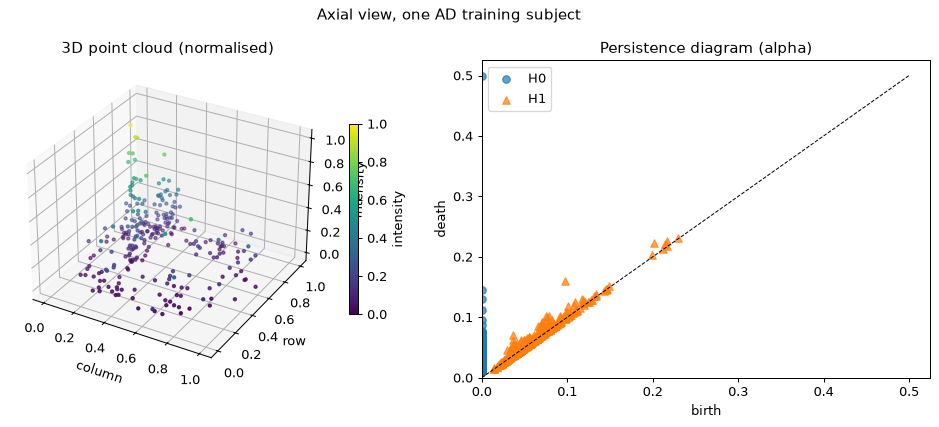

In [2]:
STEP_3D = 3
THRESHOLD_3D = {"axial": 0.5, "coronal": 0.2, "sagittal": 0.3}
FILTRATION_3D = "alpha"
MAX_RADIUS_3D = 0.5

img = data_by_view["axial"]["train_imgs"][0]
points = filtration_3d.normalize_point_cloud(filtration_3d.image_to_3d_point_cloud(img, step=STEP_3D, threshold=THRESHOLD_3D["axial"]))
diags = filtration_3d.compute_filtration_3d(points, FILTRATION_3D, max_radius=MAX_RADIUS_3D)
print(f"{len(points)} points | H0: {len(diags['diag_h0'])} features | H1: {len(diags['diag_h1'])} features")
fig = filtration_3d.plot_point_cloud_and_diagram(points, diags, title="Axial view, one AD training subject", max_radius=MAX_RADIUS_3D)
save_figure(fig, "08_3d_point_cloud_example")

In [3]:
templates_by_view = {v: compute_class_templates_for_view(data_by_view[v]["train_imgs"], y_train) for v in VIEWS}
tda_3d = {
    v: {
        part: filtration_3d.compute_tda_for_images_3d(data_by_view[v][f"{part}_imgs"], FILTRATION_3D, step=STEP_3D, threshold=THRESHOLD_3D[v], max_radius=MAX_RADIUS_3D)
        for part in ("train", "test")
    }
    for v in VIEWS
}
templates_3d = {v: filtration_3d.compute_template_tda_3d(templates_by_view[v], FILTRATION_3D, step=STEP_3D, threshold=THRESHOLD_3D[v], max_radius=MAX_RADIUS_3D) for v in VIEWS}

results_3d = [run_nearest_template_classification(tda_3d, templates_3d, y_test, VIEWS, metric=m, verbose=False)[1] for m in ("bottleneck", "wasserstein")]
logit_3d = fit_eval_logistic_multiview(tda_3d, y_train, y_test, VIEWS, C=LOGIT_C, verbose=False, feature_set="landscape_betti", name="Logistic regression")
results_3d += [logit_3d["metrics_train"], logit_3d["metrics_test"]]
cv_3d = cross_validate_logistic_multiview(tda_3d, y_train, y_test, VIEWS, C=LOGIT_C, feature_set="landscape_betti")
summarize_results(results_3d).round(3)

,model,split,accuracy,balanced_accuracy
0,Nearest template (bottleneck),test,0.50,0.50
1,Nearest template (wasserstein),test,0.45,0.45
2,Logistic regression,train,1.00,1.00
3,Logistic regression,test,0.50,0.50


## B. Adaptive (quantile) thresholds

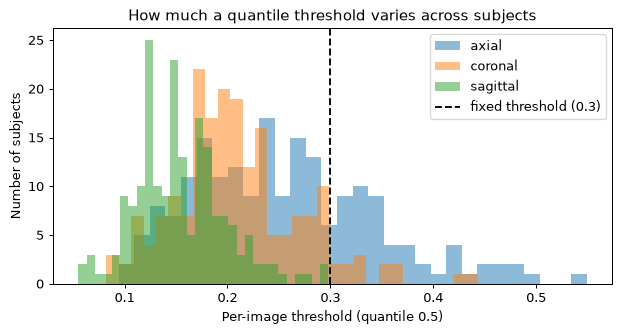

In [4]:
QUANTILE = 0.5
QUANTILE_FILTRATIONS = ["lower_star", "alpha"]

fig, ax = plt.subplots(figsize=(7, 3.8))
for v in VIEWS:
    thr = [np.quantile(im, QUANTILE) for im in data_by_view[v]["train_imgs"]]
    ax.hist(thr, bins=30, alpha=0.5, label=v)
ax.axvline(0.3, color="k", linestyle="--", label="fixed threshold (0.3)")
ax.set(xlabel=f"Per-image threshold (quantile {QUANTILE})", ylabel="Number of subjects", title="How much a quantile threshold varies across subjects")
ax.legend()
fig.tight_layout()
save_figure(fig, "08_quantile_thresholds")

In [5]:
results_q, cv_q = {}, {}
for ftype in QUANTILE_FILTRATIONS:
    tda_q = {v: {part: compute_tda_for_images(data_by_view[v][f"{part}_imgs"], filtration_type=ftype, quantile=QUANTILE) for part in ("train", "test")} for v in VIEWS}
    templates_q = {v: compute_class_template_tda_quantile(data_by_view[v]["train_imgs"], y_train, QUANTILE, filtration_type=ftype) for v in VIEWS}
    res = [run_nearest_template_classification(tda_q, templates_q, y_test, VIEWS, metric=m, verbose=False)[1] for m in ("bottleneck", "wasserstein")]
    logit_q = fit_eval_logistic_multiview(tda_q, y_train, y_test, VIEWS, C=LOGIT_C, verbose=False, name="Logistic regression")
    results_q[ftype] = res + [logit_q["metrics_train"], logit_q["metrics_test"]]
    cv_q[ftype] = cross_validate_logistic_multiview(tda_q, y_train, y_test, VIEWS, C=LOGIT_C)

## Summary

In [6]:
rows = [{**m, "name": f"3D alpha: {m['name']}"} for m in results_3d]
for ftype, res in results_q.items():
    rows += [{**m, "name": f"quantile {ftype}: {m['name']}"} for m in res]
summary = summarize_results(rows)
save_table(summary, "08_3d_and_quantile_results")

cv_table = pd.DataFrame([{"pipeline": "3D alpha", **cv_3d}] + [{"pipeline": f"quantile {f}", **cv_q[f]} for f in QUANTILE_FILTRATIONS])
save_table(cv_table, "08_3d_and_quantile_cv")
display(summary.round(3))
cv_table.round(3)

,model,split,accuracy,balanced_accuracy
0,3D alpha: Nearest template (bottleneck),test,0.500,0.500
1,3D alpha: Nearest template (wasserstein),test,0.450,0.450
2,3D alpha: Logistic regression,train,1.000,1.000
3,3D alpha: Logistic regression,test,0.500,0.500
4,quantile lower_star: Nearest template (bottlen...,test,0.550,0.550
5,quantile lower_star: Nearest template (wassers...,test,0.600,0.600
6,quantile lower_star: Logistic regression,train,0.984,0.984
7,quantile lower_star: Logistic regression,test,0.950,0.950
8,quantile alpha: Nearest template (bottleneck),test,0.650,0.650
9,quantile alpha: Nearest template (wasserstein),test,0.600,0.600


,pipeline,cv_accuracy_mean,cv_accuracy_std,cv_balanced_accuracy_mean,cv_balanced_accuracy_std
0,3D alpha,0.704,0.051,0.704,0.051
1,quantile lower_star,0.720,0.059,0.720,0.059
2,quantile alpha,0.558,0.069,0.558,0.069


**Reading the results.**

- **Adaptive thresholds help the lower-star filtration**: CV balanced
  accuracy rises from ≈ 0.67 (fixed threshold, notebook 06) to ≈ 0.72.
  Normalising away each scan's overall brightness removes a nuisance factor.
- **They hurt the alpha filtration** (≈ 0.67 → ≈ 0.56). A likely reason: for
  point clouds a fixed threshold carries real information, how *much* of the brain is above
  a given uptake level. A quantile threshold keeps the same amount for every
  subject and throws that away.
- **3D alpha** (≈ 0.70 in CV) improves on 2D alpha (≈ 0.67), so adding
  intensity as a coordinate helps. Its 20-subject test accuracy (0.50) is far
  below the CV estimate, a reminder of how noisy the fixed test set is.